## Verification of Fluxes

In [8]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [14]:
ds = xr.open_dataset('/jetfs/scratch/gbrack/MSC/ERA_SHF_LHF_Pr.nc')

In [15]:
ds.sshf

<xarray.DataArray 'sshf' (valid_time: 1464, latitude: 241, longitude: 561)> Size: 792MB
[197934264 values with dtype=float32]
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 12kB 2015-05-01 ... 2015-06-30T23...
  * latitude    (latitude) float64 2kB 50.0 49.75 49.5 ... -9.5 -9.75 -10.0
  * longitude   (longitude) float64 4kB 10.0 10.25 10.5 ... 149.5 149.8 150.0
    expver      (valid_time) <U4 23kB ...
Attributes: (12/32)
    GRIB_paramId:                             146
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      135201
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    long_name:                                Time-integrated surface sensibl...
    units:                                    J m**-2
    standard_name:                            surface_upward_sensible_heat_flux
    GRIB_surface:                             0.0

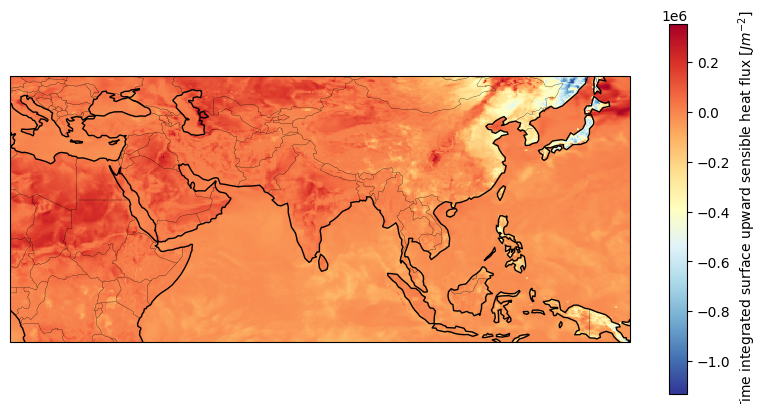

In [16]:
fig, ax = plt.subplots(1, 1, figsize = (10, 6),
                      subplot_kw={'projection': ccrs.PlateCarree()})

mesh = ax.pcolormesh(ds.longitude, ds.latitude, ds.sshf.isel(valid_time=0).squeeze(), cmap='RdYlBu_r')
cbar = plt.colorbar(mesh, ax=ax, shrink=0.8, label=r"Time integrated surface upward sensible heat flux $[Jm^{-2}]$")
ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS, lw=0.2)